In [1]:
!pip install -q --upgrade gradio


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


In [2]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.transforms import v2

import tensorflow as tf
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Éviter que TensorFlow ne bloque la mémoire GPU de PyTorch
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

celeb_matches = glob.glob("/kaggle/input/**/Celeb_V2", recursive=True)
csv_matches   = sorted(glob.glob("/kaggle/input/**/split_par_video.csv", recursive=True))
keras_matches = sorted(glob.glob("/kaggle/input/**/cnn_simple.keras", recursive=True))

RACINE     = celeb_matches[0]
CSV_PATH   = csv_matches[0]
KERAS_PATH = keras_matches[0]

print("RACINE     :", RACINE)
print("CSV_PATH   :", CSV_PATH)
print("KERAS_PATH :", KERAS_PATH)

df = pd.read_csv(CSV_PATH)
print(df["split"].value_counts())
assert df.groupby("video")["split"].nunique().max() == 1


I0000 00:00:1793999045.926801      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Device : cuda
RACINE     : /kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2
CSV_PATH   : /kaggle/input/datasets/ahmedyassinemetkoul/livrable-etudiant-1/split_par_video.csv
KERAS_PATH : /kaggle/input/datasets/ahmedyassinemetkoul/livrable-etudiant-1/cnn_simple.keras
split
train    80798
test     10155
val      10078
Name: count, dtype: int64


In [3]:
IMG_SIZE = 128
paths = (RACINE + "/" + df.rel_path).values

def lire(p):
    return np.asarray(Image.open(p).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))

X = np.empty((len(df), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
with ThreadPoolExecutor(8) as ex:
    for i, arr in enumerate(tqdm(ex.map(lire, paths), total=len(paths))):
        X[i] = arr

y = df.label.values.astype("float32")

masque = {s: (df.split.values == s) for s in ["train", "val", "test"]}
X_train, y_train = X[masque["train"]], y[masque["train"]]
X_val,   y_val   = X[masque["val"]],   y[masque["val"]]
X_test,  y_test  = X[masque["test"]],  y[masque["test"]]
del X

print(X_train.shape, X_val.shape, X_test.shape)


  0%|          | 0/101031 [00:00<?, ?it/s]

(80798, 128, 128, 3) (10078, 128, 128, 3) (10155, 128, 128, 3)


In [4]:
weights = ResNet18_Weights.DEFAULT
mean = weights.transforms().mean
std  = weights.transforms().std

train_transform = v2.Compose([
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomRotation(degrees=18),
    v2.ColorJitter(brightness=0.1, contrast=0.1),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=mean, std=std),
])

eval_transform = v2.Compose([
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=mean, std=std),
])

class ImageDataset(Dataset):
    def __init__(self, X, y, transform=None):
        self.X = X
        self.y = y
        self.transform = transform

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i]).permute(2, 0, 1)
        if self.transform:
            x = self.transform(x)
        return x, torch.tensor(self.y[i], dtype=torch.float32)

BATCH = 64
train_loader = DataLoader(ImageDataset(X_train, y_train, train_transform), batch_size=BATCH, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(ImageDataset(X_val,   y_val,   eval_transform),  batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(ImageDataset(X_test,  y_test,  eval_transform),  batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)


In [5]:
model = resnet18(weights=weights)
for param in model.parameters():
    param.requires_grad = False

model.fc = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(model.fc.in_features, 1)
)
model = model.to(device)

criterion = nn.BCEWithLogitsLoss()

def step_epoch(loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum = 0.0
    probs_list, targets_list = [], []

    with torch.set_grad_enabled(training):
        for x, y_b in loader:
            x, y_b = x.to(device), y_b.to(device).unsqueeze(1)
            if training:
                optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y_b)
            if training:
                loss.backward()
                optimizer.step()

            loss_sum += loss.item() * len(y_b)
            probs_list.append(torch.sigmoid(out).detach().cpu().numpy().ravel())
            targets_list.append(y_b.detach().cpu().numpy().ravel())

    probs = np.concatenate(probs_list)
    targets = np.concatenate(targets_list)
    preds = (probs > 0.5).astype(int)

    return {
        "loss": loss_sum / len(loader.dataset),
        "accuracy": accuracy_score(targets, preds),
        "precision": precision_score(targets, preds, zero_division=0),
        "recall": recall_score(targets, preds, zero_division=0),
        "auc": roc_auc_score(targets, probs),
    }

history = []
best_val_loss = float("inf")
patience, wait = 4, 0

# Phase 1 : Couche finale uniquement (3 époques)
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
for epoch in range(1, 4):
    tr = step_epoch(train_loader, optimizer)
    va = step_epoch(val_loader)
    history.append({"epoch": epoch, **{k: tr[k] for k in tr}, **{f"val_{k}": va[k] for k in va}})
    print(f"Epoch {epoch:02d} [Head] - loss: {tr['loss']:.4f} - acc: {tr['accuracy']:.4f} - val_loss: {va['loss']:.4f} - val_acc: {va['accuracy']:.4f} - val_auc: {va['auc']:.4f}")
    if va["loss"] < best_val_loss:
        best_val_loss = va["loss"]
        torch.save(model.state_dict(), "/kaggle/working/resnet18.pt")

# Phase 2 : Fine-tuning de tout le réseau
for param in model.parameters():
    param.requires_grad = True

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

for epoch in range(4, 20):
    tr = step_epoch(train_loader, optimizer)
    va = step_epoch(val_loader)
    scheduler.step(va["loss"])
    history.append({"epoch": epoch, **{k: tr[k] for k in tr}, **{f"val_{k}": va[k] for k in va}})
    print(f"Epoch {epoch:02d} [Fine] - loss: {tr['loss']:.4f} - acc: {tr['accuracy']:.4f} - val_loss: {va['loss']:.4f} - val_acc: {va['accuracy']:.4f} - val_auc: {va['auc']:.4f}")

    if va["loss"] < best_val_loss:
        best_val_loss = va["loss"]
        wait = 0
        torch.save(model.state_dict(), "/kaggle/working/resnet18.pt")
    else:
        wait += 1
        if wait >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

pd.DataFrame(history).to_csv("/kaggle/working/resnet18_history.csv", index=False)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 183MB/s] 


Epoch 01 [Head] - loss: 0.6570 - acc: 0.6164 - val_loss: 0.6485 - val_acc: 0.6309 - val_auc: 0.6747
Epoch 03 [Head] - loss: 0.6463 - acc: 0.6273 - val_loss: 0.6518 - val_acc: 0.6225 - val_auc: 0.6652
Epoch 04 [Fine] - loss: 0.2184 - acc: 0.9068 - val_loss: 0.2660 - val_acc: 0.9137 - val_auc: 0.9683
Epoch 05 [Fine] - loss: 0.0923 - acc: 0.9647 - val_loss: 0.2094 - val_acc: 0.9278 - val_auc: 0.9817
Epoch 06 [Fine] - loss: 0.0645 - acc: 0.9760 - val_loss: 0.2135 - val_acc: 0.9251 - val_auc: 0.9841
Epoch 07 [Fine] - loss: 0.0532 - acc: 0.9807 - val_loss: 0.1878 - val_acc: 0.9285 - val_auc: 0.9851
Epoch 08 [Fine] - loss: 0.0436 - acc: 0.9836 - val_loss: 0.1935 - val_acc: 0.9326 - val_auc: 0.9881
Epoch 09 [Fine] - loss: 0.0383 - acc: 0.9862 - val_loss: 0.1734 - val_acc: 0.9399 - val_auc: 0.9853
Epoch 10 [Fine] - loss: 0.0353 - acc: 0.9875 - val_loss: 0.2976 - val_acc: 0.9088 - val_auc: 0.9829
Epoch 11 [Fine] - loss: 0.0315 - acc: 0.9887 - val_loss: 0.2283 - val_acc: 0.9322 - val_auc: 0.9856


=== ResNet18 (Étudiant 2) ===
              precision    recall  f1-score   support

        real      0.943     0.919     0.931      5082
        fake      0.921     0.945     0.933      5073

    accuracy                          0.932     10155
   macro avg      0.932     0.932     0.932     10155
weighted avg      0.932     0.932     0.932     10155

=== CNN Simple (Étudiant 1) ===
              precision    recall  f1-score   support

        real      0.878     0.924     0.900      5082
        fake      0.920     0.871     0.895      5073

    accuracy                          0.898     10155
   macro avg      0.899     0.898     0.898     10155
weighted avg      0.899     0.898     0.898     10155



,Modèle,Accuracy,AUC,Precision Fake,Recall Fake,F1 Fake,F1 Real
0,CNN Simple (Étudiant 1),0.8977,0.9623,0.9195,0.8715,0.8948,0.9004
1,ResNet18 (Étudiant 2),0.9321,0.9826,0.9212,0.9448,0.9329,0.9312


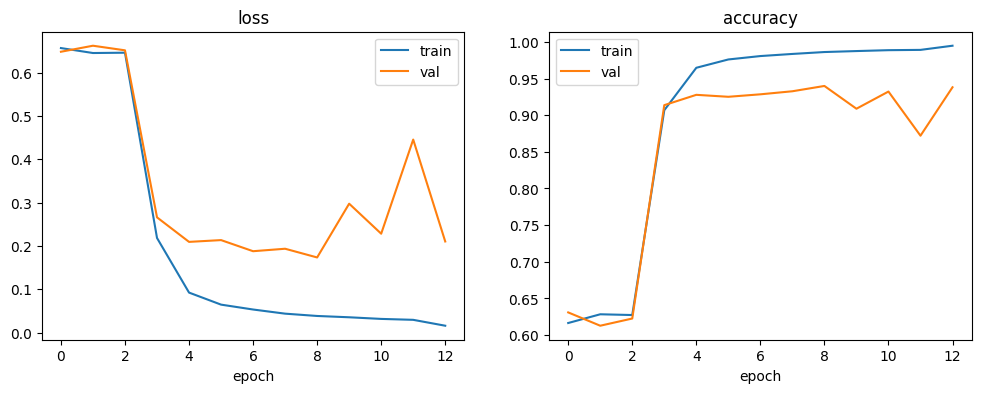

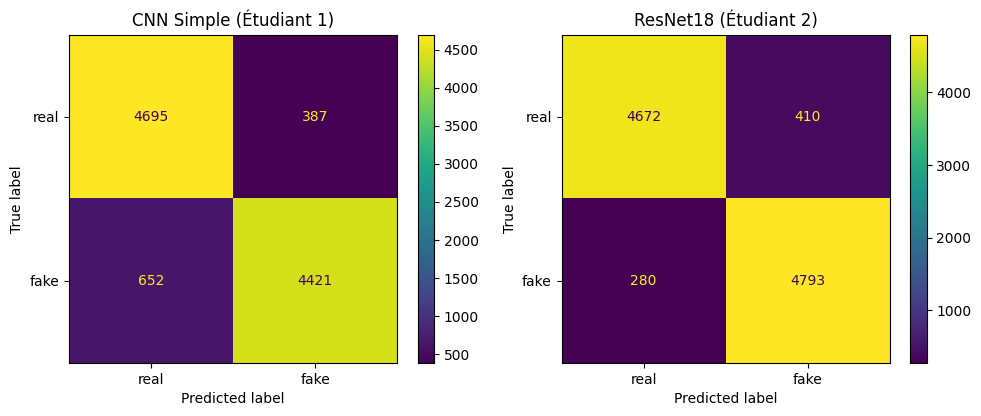

In [6]:
model.load_state_dict(torch.load("/kaggle/working/resnet18.pt", map_location=device, weights_only=True))
model.eval()

y_prob_res = []
with torch.no_grad():
    for x, _ in test_loader:
        out = model(x.to(device))
        y_prob_res.append(torch.sigmoid(out).cpu().numpy().ravel())

y_prob_res = np.concatenate(y_prob_res)
y_pred_res = (y_prob_res > 0.5).astype(int)
y_true = y_test.astype(int)

modele_cnn = tf.keras.models.load_model(KERAS_PATH)
y_prob_cnn = modele_cnn.predict(X_test, batch_size=64, verbose=0).ravel()
y_pred_cnn = (y_prob_cnn > 0.5).astype(int)

print("=== ResNet18 (Étudiant 2) ===")
print(classification_report(y_true, y_pred_res, target_names=["real", "fake"], digits=3))

print("=== CNN Simple (Étudiant 1) ===")
print(classification_report(y_true, y_pred_cnn, target_names=["real", "fake"], digits=3))

comparaison_df = pd.DataFrame([
    {
        "Modèle": "CNN Simple (Étudiant 1)",
        "Accuracy": round(accuracy_score(y_true, y_pred_cnn), 4),
        "AUC": round(roc_auc_score(y_true, y_prob_cnn), 4),
        "Precision Fake": round(precision_score(y_true, y_pred_cnn, pos_label=1), 4),
        "Recall Fake": round(recall_score(y_true, y_pred_cnn, pos_label=1), 4),
        "F1 Fake": round(f1_score(y_true, y_pred_cnn, pos_label=1), 4),
        "F1 Real": round(f1_score(y_true, y_pred_cnn, pos_label=0), 4),
    },
    {
        "Modèle": "ResNet18 (Étudiant 2)",
        "Accuracy": round(accuracy_score(y_true, y_pred_res), 4),
        "AUC": round(roc_auc_score(y_true, y_prob_res), 4),
        "Precision Fake": round(precision_score(y_true, y_pred_res, pos_label=1), 4),
        "Recall Fake": round(recall_score(y_true, y_pred_res, pos_label=1), 4),
        "F1 Fake": round(f1_score(y_true, y_pred_res, pos_label=1), 4),
        "F1 Real": round(f1_score(y_true, y_pred_res, pos_label=0), 4),
    }
])
comparaison_df.to_csv("/kaggle/working/comparaison_modeles.csv", index=False)
display(comparaison_df)

hist_df = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, m in enumerate(["loss", "accuracy"]):
    ax[i].plot(hist_df[m], label="train")
    ax[i].plot(hist_df["val_" + m], label="val")
    ax[i].set_title(m); ax[i].set_xlabel("epoch"); ax[i].legend()
plt.savefig("/kaggle/working/resnet18_courbes.png", dpi=150)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred_cnn), display_labels=["real", "fake"]).plot(ax=ax[0])
ax[0].set_title("CNN Simple (Étudiant 1)")
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred_res), display_labels=["real", "fake"]).plot(ax=ax[1])
ax[1].set_title("ResNet18 (Étudiant 2)")
plt.tight_layout()
plt.savefig("/kaggle/working/resnet18_confusion.png", dpi=150)
plt.show()


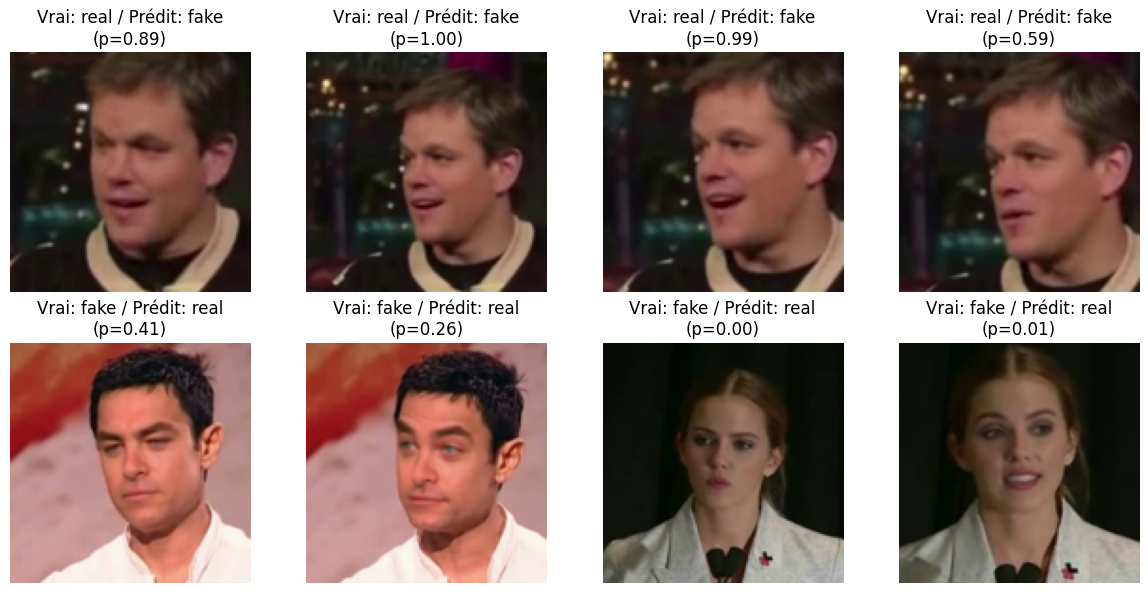

In [7]:
fp_idx = np.where((y_true == 0) & (y_pred_res == 1))[0]
fn_idx = np.where((y_true == 1) & (y_pred_res == 0))[0]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i in range(4):
    if i < len(fp_idx):
        idx = fp_idx[i]
        axes[0, i].imshow(X_test[idx])
        axes[0, i].set_title(f"Vrai: real / Prédit: fake\n(p={y_prob_res[idx]:.2f})")
        axes[0, i].axis("off")
    if i < len(fn_idx):
        idx = fn_idx[i]
        axes[1, i].imshow(X_test[idx])
        axes[1, i].set_title(f"Vrai: fake / Prédit: real\n(p={y_prob_res[idx]:.2f})")
        axes[1, i].axis("off")
plt.tight_layout()
plt.savefig("/kaggle/working/resnet18_erreurs.png", dpi=150)
plt.show()


In [8]:
!pip install -q gradio
import gradio as gr

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

def extraire_visages(video_path, n_frames=12):
    cap = cv2.VideoCapture(video_path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total <= 0:
        cap.release()
        return []
    indices = np.linspace(0, max(total - 1, 0), n_frames, dtype=int)
    visages = []
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret, frame = cap.read()
        if not ret:
            continue
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        faces = face_cascade.detectMultiScale(gray, 1.1, 5, minSize=(60, 60))
        if len(faces) > 0:
            x, y, w, h = sorted(faces, key=lambda b: b[2] * b[3], reverse=True)[0]
            crop = rgb[y:y+h, x:x+w]
        else:
            h, w, _ = rgb.shape
            m = min(h, w)
            crop = rgb[(h-m)//2:(h+m)//2, (w-m)//2:(w+m)//2]
        visages.append(np.asarray(Image.fromarray(crop).resize((IMG_SIZE, IMG_SIZE))))
    cap.release()
    return visages

def predire_visages(visages_list):
    batch_pt = torch.stack([
        eval_transform(torch.from_numpy(v).permute(2, 0, 1)) for v in visages_list
    ]).to(device)
    with torch.no_grad():
        p_res = float(torch.sigmoid(model(batch_pt)).mean().item())

    batch_tf = np.array(visages_list, dtype=np.uint8)
    p_cnn = float(modele_cnn.predict(batch_tf, verbose=0).mean())

    return (
        {"fake": p_res, "real": 1.0 - p_res},
        {"fake": p_cnn, "real": 1.0 - p_cnn}
    )

def tester_video(video_path):
    if video_path is None:
        return None, None, []
    visages = extraire_visages(video_path)
    if not visages:
        return None, None, []
    res_out, cnn_out = predire_visages(visages)
    return res_out, cnn_out, visages

def tester_image(img_np):
    if img_np is None:
        return None, None
    img_128 = np.asarray(Image.fromarray(img_np).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
    return predire_visages([img_128])

with gr.Blocks(title="Détection de Deepfakes") as demo:
    gr.Markdown("## Détection de Deepfakes : ResNet18 vs CNN Simple")
    with gr.Tab("Vidéo"):
        with gr.Row():
            vid_in = gr.Video(label="Vidéo")
            with gr.Column():
                out_res_v = gr.Label(label="ResNet18 (Étudiant 2)")
                out_cnn_v = gr.Label(label="CNN Simple (Étudiant 1)")
        gal = gr.Gallery(label="Visages extraits", columns=6)
        gr.Button("Analyser la vidéo").click(tester_video, inputs=vid_in, outputs=[out_res_v, out_cnn_v, gal])

    with gr.Tab("Image"):
        with gr.Row():
            img_in = gr.Image(type="numpy", label="Visage")
            with gr.Column():
                out_res_i = gr.Label(label="ResNet18 (Étudiant 2)")
                out_cnn_i = gr.Label(label="CNN Simple (Étudiant 1)")
        gr.Button("Analyser l'image").click(tester_image, inputs=img_in, outputs=[out_res_i, out_cnn_i])

demo.launch(share=True, prevent_thread_lock=True)


* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://98770177f434416c3a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
